# ДЗ до теми 4: прогноз міцності бетону

Студент: Фарід Джафарлі

Набір даних Concrete Strength Prediction з Kaggle містить склад бетонної суміші (цемент, шлак, зола, вода, суперпластифікатор, крупний і дрібний заповнювач), вік зразка в днях і міцність бетону в МПа. Задача: навчити нейронну мережу на PyTorch прогнозувати міцність.

## 1. Імпорт бібліотек

In [1]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()
torch.set_num_threads(1)  # same results on every run

## 2. Завантаження даних

In [2]:
csv_path = Path('data') / 'ConcreteStrengthData.csv'
if not csv_path.exists():
    # no local copy: download the dataset from Kaggle
    import kagglehub
    folder = Path(kagglehub.dataset_download('mchilamwar/predict-concrete-strength'))
    csv_path = next(folder.rglob('*.csv'))

df = pd.read_csv(csv_path)
df.columns = df.columns.str.strip()
df = df.rename(columns={
    'CementComponent': 'Cement',
    'BlastFurnaceSlag': 'Slag',
    'FlyAshComponent': 'FlyAsh',
    'WaterComponent': 'Water',
    'SuperplasticizerComponent': 'Superplasticizer',
    'CoarseAggregateComponent': 'CoarseAggregate',
    'FineAggregateComponent': 'FineAggregate',
    'AgeInDays': 'Age',
})
print(df.shape)
df.head()

(1030, 9)


,Cement,Slag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


## 3. Попередній аналіз даних

In [3]:
df.info()
df.describe().T.round(1)

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Cement            1030 non-null   float64
 1   Slag              1030 non-null   float64
 2   FlyAsh            1030 non-null   float64
 3   Water             1030 non-null   float64
 4   Superplasticizer  1030 non-null   float64
 5   CoarseAggregate   1030 non-null   float64
 6   FineAggregate     1030 non-null   float64
 7   Age               1030 non-null   int64  
 8   Strength          1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


,count,mean,std,min,25%,50%,75%,max
Cement,1030.0,281.2,104.5,102.0,192.4,272.9,350.0,540.0
Slag,1030.0,73.9,86.3,0.0,0.0,22.0,143.0,359.4
FlyAsh,1030.0,54.2,64.0,0.0,0.0,0.0,118.3,200.1
Water,1030.0,181.6,21.4,121.8,164.9,185.0,192.0,247.0
Superplasticizer,1030.0,6.2,6.0,0.0,0.0,6.4,10.2,32.2
CoarseAggregate,1030.0,972.9,77.8,801.0,932.0,968.0,1029.4,1145.0
FineAggregate,1030.0,773.6,80.2,594.0,731.0,779.5,824.0,992.6
Age,1030.0,45.7,63.2,1.0,7.0,28.0,56.0,365.0
Strength,1030.0,35.8,16.7,2.3,23.7,34.4,46.1,82.6


In [4]:
print('Пропусків:', df.isna().sum().sum())
print('Повних дублікатів:', df.duplicated().sum())
print('Різних значень віку:', df['Age'].nunique())

Пропусків: 0
Повних дублікатів: 25
Різних значень віку: 14


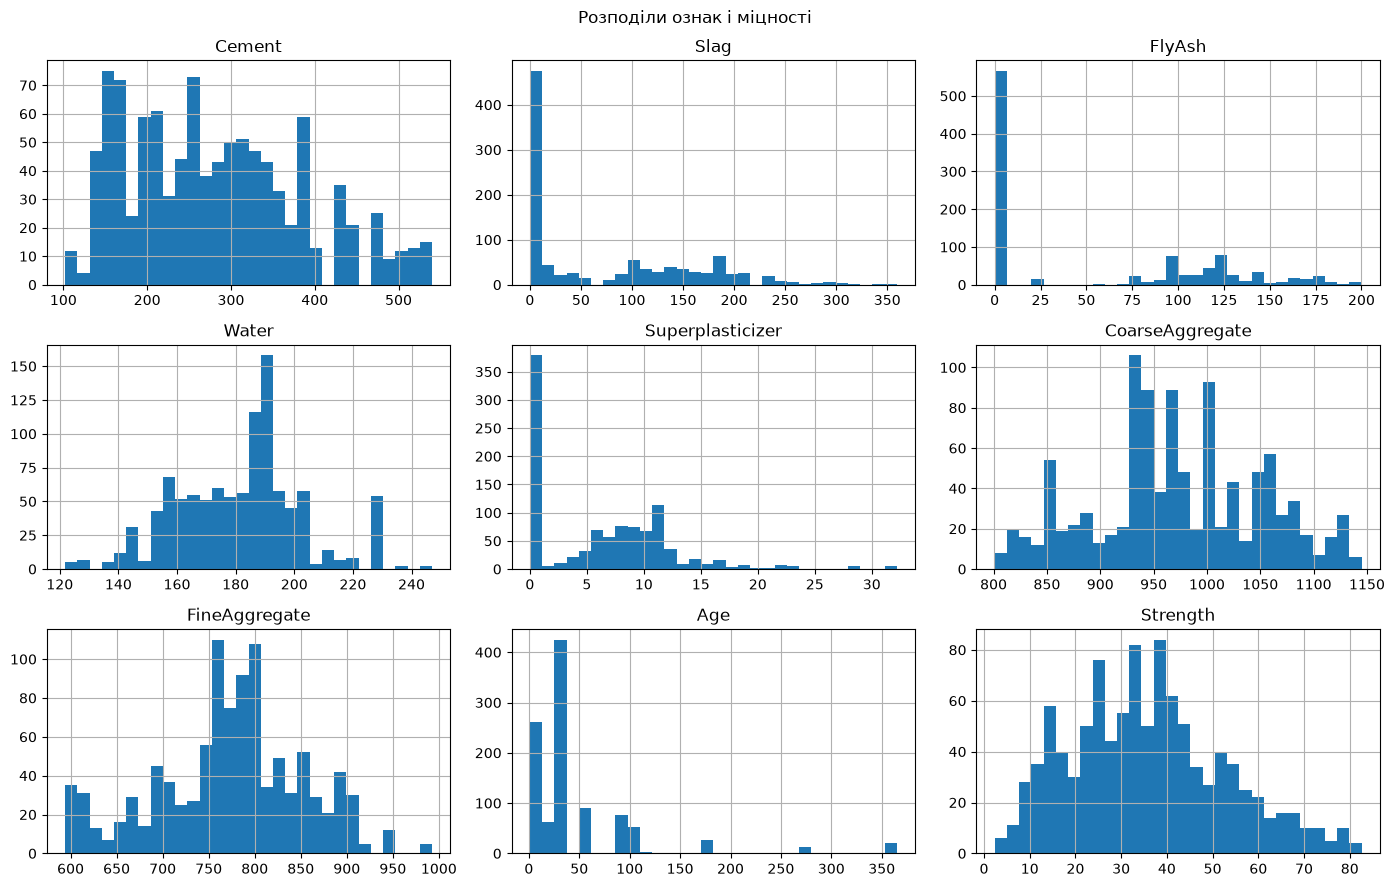

In [5]:
df.hist(bins=30, figsize=(14, 9))
plt.suptitle('Розподіли ознак і міцності')
plt.tight_layout()
plt.show()

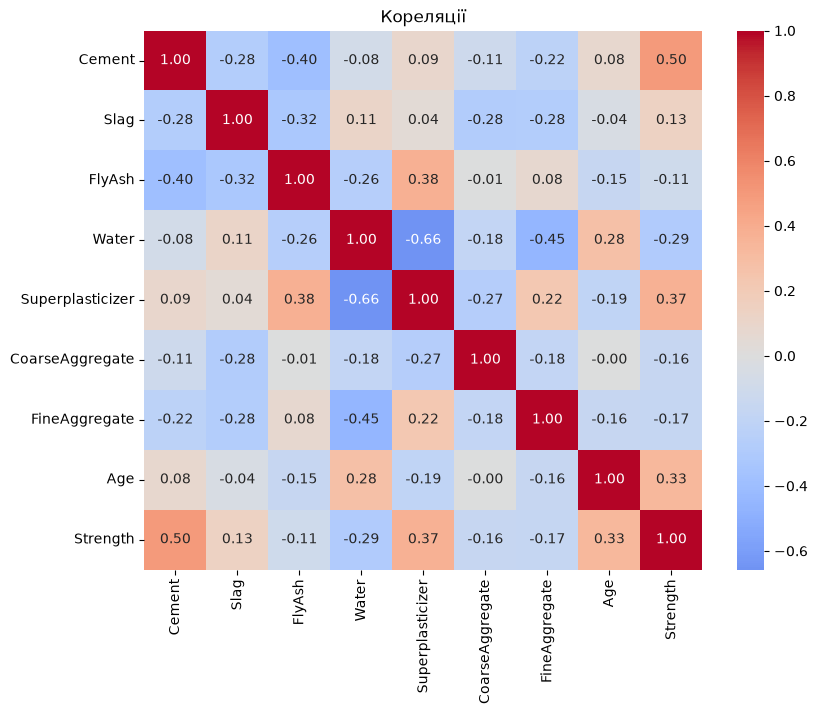

In [6]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Кореляції')
plt.show()

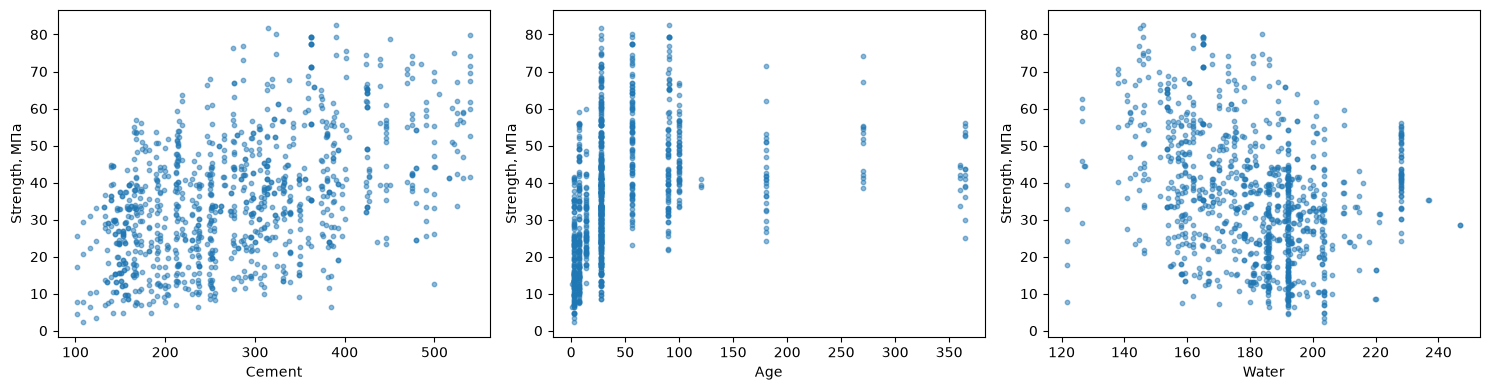

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Cement', 'Age', 'Water']):
    ax.scatter(df[col], df['Strength'], s=10, alpha=0.5)
    ax.set_xlabel(col)
    ax.set_ylabel('Strength, МПа')
plt.tight_layout()
plt.show()

Що видно з аналізу:
- пропусків немає, але є 25 повних дублікатів;
- міцність від 2.3 до 82.6 МПа, у середньому 35.8 МПа;
- найсильніше з міцністю пов'язані цемент (кореляція 0.50), суперпластифікатор (0.37) і вік (0.33). Вода пов'язана у зворотний бік (-0.29): чим більше води, тим слабший бетон;
- вік має лише 14 різних значень, і 73% зразків не старші за 28 днів. Міцність швидко росте в перші тижні, а після 100 днів майже не змінюється;
- ознаки мають дуже різний масштаб, від кількох одиниць до тисячі, тому їх треба нормалізувати.

## 4. Підготовка даних

Дублікати я прибираю, щоб однакові рядки не опинилися одночасно в навчальному і тестовому наборі. Категоріальних ознак у даних немає, тому кодувати нічого не потрібно.

Дані ділю на три частини: 70% для навчання, 15% для валідації (за нею я стежу під час навчання і вибираю найкращу модель) і 15% для тесту (його використовую тільки для фінальної оцінки). StandardScaler навчаю лише на навчальній частині, щоб інформація з тесту не потрапила в модель.

In [8]:
df = df.drop_duplicates().reset_index(drop=True)

X = df.drop(columns='Strength').values
y = df['Strength'].values

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=SEED)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)


def to_tensor(a):
    return torch.tensor(a, dtype=torch.float32)


X_train_t, y_train_t = to_tensor(X_train), to_tensor(y_train).view(-1, 1)
X_val_t, y_val_t = to_tensor(X_val), to_tensor(y_val).view(-1, 1)

print('train:', X_train.shape, 'validation:', X_val.shape, 'test:', X_test.shape)

train: (703, 8) validation: (151, 8) test: (151, 8)


## 5. Модель

На вході 8 ознак, далі два приховані шари на 64 і 32 нейрони з активацією ReLU, на виході один нейрон, бо треба передбачити одне число. На виході активації немає, бо міцність може бути будь-яким числом.

Даних небагато, близько тисячі рядків, тому велика мережа тут не потрібна. Двох шарів вистачає, щоб вловити нелінійні залежності, а параметрів мало, тож мережа не так швидко перенавчається.

In [9]:
class ConcreteNet(nn.Module):
    def __init__(self, n_inputs, hidden=(64, 32)):
        super().__init__()
        layers = []
        prev = n_inputs
        for size in hidden:
            layers += [nn.Linear(prev, size), nn.ReLU()]
            prev = size
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


print(ConcreteNet(X_train.shape[1]))

ConcreteNet(
  (net): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


## 6. Налаштування і навчання

Функція втрат MSELoss. Це задача регресії, і для неї це стандартний вибір. MSE сильніше штрафує великі помилки, а для міцності бетону одна велика помилка гірша за кілька маленьких. Крім того, MSE є однією з метрик у завданні, тож модель вчиться саме на тому, за чим її оцінюють.

Оптимізатор SGD, як пропонує інструкція.

Гіперпараметри:
- швидкість навчання 0.01: звичайне стартове значення для SGD;
- розмір батчу 32: на 703 рядках це 22 оновлення ваг за епоху;
- 300 епох: як видно на графіку нижче, валідаційна помилка перестає падати задовго до кінця навчання, тож епох достатньо.

Після кожної епохи я рахую помилку на валідації і в кінці повертаю ваги з найкращої епохи.

In [10]:
def train_model(model, optimizer, epochs=300, batch_size=32, log_every=50):
    loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size,
                        shuffle=True, generator=torch.Generator().manual_seed(SEED))
    loss_fn = nn.MSELoss()
    history = {'train': [], 'val': []}
    best_val, best_state = float('inf'), None

    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
        train_loss = total / len(X_train_t)

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_val_t), y_val_t).item()

        history['train'].append(train_loss)
        history['val'].append(val_loss)
        if val_loss < best_val:
            best_val = val_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        if log_every and (epoch == 1 or epoch % log_every == 0):
            print(f'Епоха {epoch:3d}: train MSE {train_loss:7.2f}, val MSE {val_loss:7.2f}')

    model.load_state_dict(best_state)
    if log_every:
        print(f'Найкраща val MSE: {best_val:.2f}')
    return history

In [11]:
set_seed()
model = ConcreteNet(X_train.shape[1])
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
history = train_model(model, optimizer)

Епоха   1: train MSE 1061.41, val MSE  939.03


Епоха  50: train MSE   22.05, val MSE   58.02


Епоха 100: train MSE   15.50, val MSE   41.37


Епоха 150: train MSE    9.47, val MSE   39.61


Епоха 200: train MSE    8.08, val MSE   40.03


Епоха 250: train MSE    7.14, val MSE   39.56


Епоха 300: train MSE    7.92, val MSE   41.25
Найкраща val MSE: 37.30


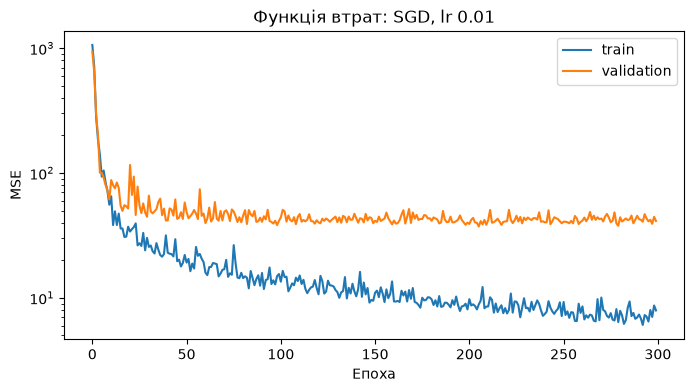

In [12]:
def plot_history(history, title):
    plt.figure(figsize=(8, 4))
    plt.plot(history['train'], label='train')
    plt.plot(history['val'], label='validation')
    plt.yscale('log')
    plt.xlabel('Епоха')
    plt.ylabel('MSE')
    plt.title(title)
    plt.legend()
    plt.show()


plot_history(history, 'Функція втрат: SGD, lr 0.01')

Помилка на навчальних даних падає весь час, а на валідації вже після 50-100 епох майже не змінюється. Найменша валідаційна помилка була на 206 епосі, ці ваги і залишаються в моделі. Те, що помилка на навчальних даних далі падає, а на валідації ні, означає, що мережа починає перенавчатися.

## 7. Оцінка моделі

Метрики:
- MSE: середній квадрат помилки, та сама величина, що і функція втрат;
- MAE: на скільки МПа модель помиляється в середньому, її найпростіше зрозуміти;
- R²: яку частку розкиду міцності пояснює модель, 1 означає ідеальний прогноз.

Для всіх трьох у завданні є орієнтовні межі, тож результат легко порівняти.

In [13]:
def predict(model, X):
    model.eval()
    with torch.no_grad():
        return model(to_tensor(X)).numpy().ravel()


def metrics(y_true, y_pred):
    return {'MSE': mean_squared_error(y_true, y_pred),
            'MAE': mean_absolute_error(y_true, y_pred),
            'R2': r2_score(y_true, y_pred)}


pd.DataFrame({
    'train': metrics(y_train, predict(model, X_train)),
    'validation': metrics(y_val, predict(model, X_val)),
    'test': metrics(y_test, predict(model, X_test)),
}).T.round(3)

,MSE,MAE,R2
train,6.780,1.733,0.973
validation,37.304,3.622,0.885
test,26.613,3.588,0.894


На тесті MSE 26.6, MAE 3.59 МПа, R² 0.894. За шкалою із завдання всі три метрики в зоні "відмінно" (MSE менше 35, MAE менше 5, R² більше 0.8). На валідації MSE вища, 37.3, а MAE і R² такі самі, як на тесті. На навчальних даних помилка набагато менша (MSE 6.8), тобто модель частково запам'ятала навчальні приклади.

## 8. Аналіз результатів

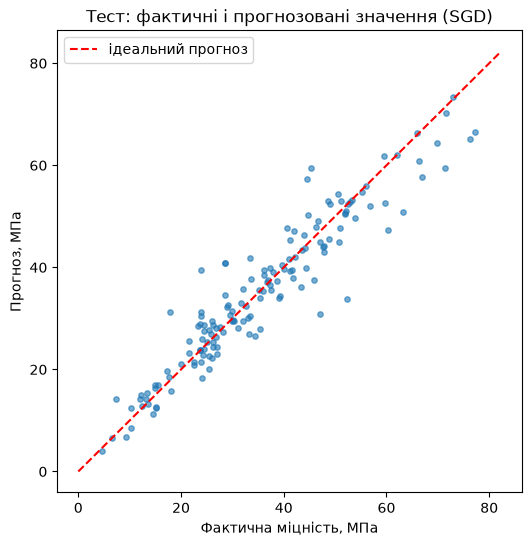

In [14]:
def plot_pred(model, title):
    y_pred = predict(model, X_test)
    plt.figure(figsize=(6, 6))
    plt.scatter(y_test, y_pred, s=15, alpha=0.6)
    lim = [0, max(y_test.max(), y_pred.max()) + 5]
    plt.plot(lim, lim, 'r--', label='ідеальний прогноз')
    plt.xlabel('Фактична міцність, МПа')
    plt.ylabel('Прогноз, МПа')
    plt.title(title)
    plt.legend()
    plt.show()


plot_pred(model, 'Тест: фактичні і прогнозовані значення (SGD)')

Більшість точок лежить близько до червоної лінії, тобто прогнози здебільшого точні. Найгірше модель прогнозує дуже міцний бетон, понад 60 МПа: там прогноз зазвичай нижчий за фактичне значення. Таких зразків у даних мало, тому модель вивчила їх гірше.

## 9. Оптимізація моделі

Я пробую три архітектури (один шар на 32 нейрони, 64 і 32, 128 і 64) і три варіанти оптимізатора: SGD з lr 0.01, Adam з lr 0.001 і Adam з lr 0.01. Найкращу модель вибираю за помилкою на валідації.

In [15]:
rows, models = [], {}
for hidden in [(32,), (64, 32), (128, 64)]:
    for opt_name, lr in [('SGD', 0.01), ('Adam', 0.001), ('Adam', 0.01)]:
        set_seed()
        m = ConcreteNet(X_train.shape[1], hidden)
        opt_class = torch.optim.SGD if opt_name == 'SGD' else torch.optim.Adam
        h = train_model(m, opt_class(m.parameters(), lr=lr), log_every=0)
        name = f'{opt_name}, lr {lr}, шари {hidden}'
        models[name] = (m, h)
        rows.append({'модель': name, 'найкраща епоха': int(np.argmin(h['val'])) + 1,
                     **metrics(y_val, predict(m, X_val))})

grid = pd.DataFrame(rows).sort_values('MSE').reset_index(drop=True).round(3)
grid

,модель,найкраща епоха,MSE,MAE,R2
0,"Adam, lr 0.01, шари (128, 64)",220,27.820,3.557,0.914
1,"Adam, lr 0.01, шари (64, 32)",294,31.375,3.800,0.903
2,"SGD, lr 0.01, шари (128, 64)",259,34.565,3.635,0.893
3,"SGD, lr 0.01, шари (64, 32)",206,37.304,3.622,0.885
4,"Adam, lr 0.001, шари (128, 64)",297,41.789,4.370,0.871
5,"SGD, lr 0.01, шари (32,)",41,44.373,4.789,0.863
6,"Adam, lr 0.001, шари (64, 32)",297,44.538,4.390,0.862
7,"Adam, lr 0.01, шари (32,)",286,52.184,5.460,0.839
8,"Adam, lr 0.001, шари (32,)",300,67.235,6.177,0.792


In [16]:
best_name = grid.loc[0, 'модель']
best_model, best_history = models[best_name]
print('Найкраща модель на валідації:', best_name)

pd.DataFrame({
    'базова SGD, validation': metrics(y_val, predict(model, X_val)),
    'базова SGD, test': metrics(y_test, predict(model, X_test)),
    'найкраща, validation': metrics(y_val, predict(best_model, X_val)),
    'найкраща, test': metrics(y_test, predict(best_model, X_test)),
}).T.round(3)

Найкраща модель на валідації: Adam, lr 0.01, шари (128, 64)


,MSE,MAE,R2
"базова SGD, validation",37.304,3.622,0.885
"базова SGD, test",26.613,3.588,0.894
"найкраща, validation",27.820,3.557,0.914
"найкраща, test",28.777,3.816,0.885


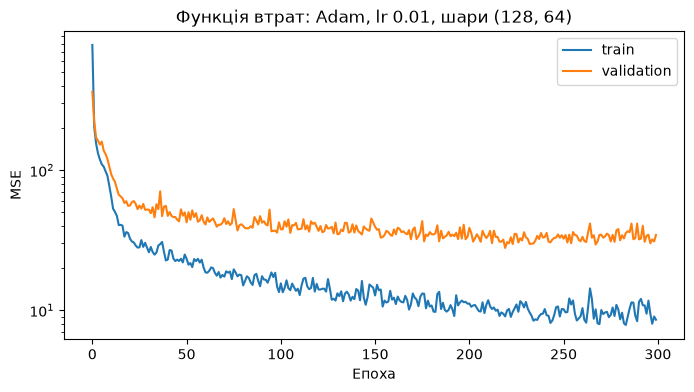

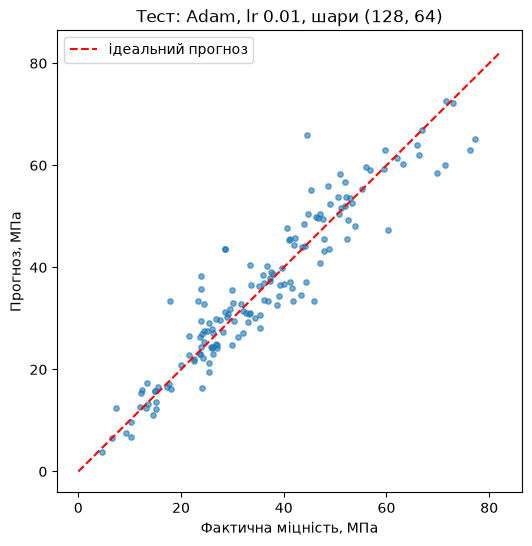

In [17]:
plot_history(best_history, f'Функція втрат: {best_name}')
plot_pred(best_model, f'Тест: {best_name}')

На валідації найкраща модель Adam з lr 0.01 і шарами 128 та 64: MSE 27.8 проти 37.3 у базової. Adam з lr 0.001 за 300 епох не встигає навчитися, його найкраща епоха майже остання. Мережа з одним шаром на 32 нейрони гірша за інші.

На тесті обидві моделі майже однакові: MSE 28.8 у найкращої і 26.6 у базової. Валідаційна і тестова частини маленькі, по 151 рядку, тому різниця в кілька одиниць MSE може бути випадковою. Фінальною я залишаю модель, вибрану за валідацією, бо за тестом моделі не вибирають.

## 10. Найважливіші фактори

Щоб побачити, які ознаки найважливіші для моделі, я по черзі перемішую значення однієї ознаки в тестовому наборі і дивлюся, наскільки зростає помилка. Чим більше зростання, тим важливіша ознака.

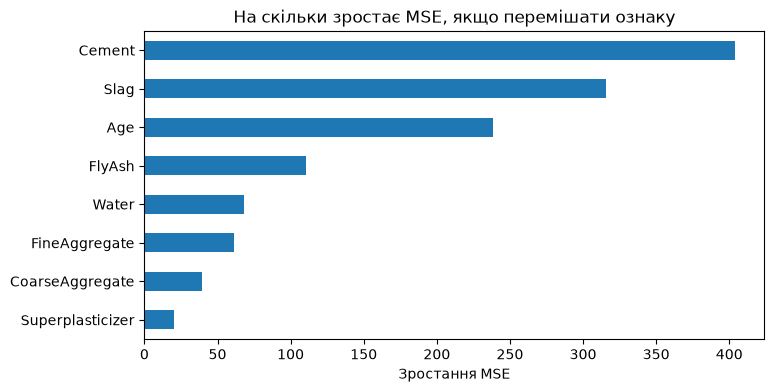

Cement              403.8
Slag                316.0
Age                 238.1
FlyAsh              110.3
Water                68.2
FineAggregate        61.4
CoarseAggregate      39.7
Superplasticizer     20.3
dtype: float64

In [18]:
feature_names = df.drop(columns='Strength').columns
base_mse = mean_squared_error(y_test, predict(best_model, X_test))
rng = np.random.default_rng(SEED)

importance = {}
for i, name in enumerate(feature_names):
    growth = []
    for _ in range(10):
        X_shuffled = X_test.copy()
        X_shuffled[:, i] = rng.permutation(X_shuffled[:, i])
        growth.append(mean_squared_error(y_test, predict(best_model, X_shuffled)) - base_mse)
    importance[name] = np.mean(growth)

importance = pd.Series(importance).sort_values()
importance.plot.barh(figsize=(8, 4), title='На скільки зростає MSE, якщо перемішати ознаку')
plt.xlabel('Зростання MSE')
plt.show()
importance.sort_values(ascending=False).round(1)

Найважливіші фактори для моделі: цемент, шлак і вік. Далі йдуть зола і вода, а найменше впливає суперпластифікатор.

Цемент і вік збігаються з кореляціями з розділу 3. Шлак має слабку кореляцію з міцністю, але модель використовує його разом з іншими компонентами суміші. Суперпластифікатор, навпаки, корелює з міцністю, але для моделі майже не важливий: він сильно пов'язаний з водою (кореляція -0.66), тож модель отримує цю інформацію через воду.

## 11. Висновки

- Мережа з двома прихованими шарами навчається стабільно. Валідаційна помилка перестає падати задовго до 300 епохи, тому я зберігаю ваги з найкращої епохи.
- Фінальна модель (Adam, lr 0.01, шари 128 і 64) на валідації має MSE 27.8, MAE 3.56 МПа і R² 0.914, на тесті MSE 28.8, MAE 3.82 МПа і R² 0.885. Це "відмінно" за всіма трьома метриками. Базова модель із SGD теж дає "відмінно".
- Найбільше на міцність впливають цемент, шлак і вік бетону.
- Слабкі місця: даних мало, модель помітно краща на навчальних даних, ніж на нових, і гірше прогнозує дуже міцний бетон. Через малі валідаційну і тестову частини оцінки трохи залежать від того, як поділені дані.

Що можна покращити:
- перевіряти моделі крос-валідацією замість одного поділу, щоб оцінки були стабільнішими;
- додати dropout або weight decay, щоб зменшити перенавчання;
- перетворити вік, наприклад взяти від нього логарифм, бо міцність росте з віком нерівномірно;
- навчити кілька мереж і усереднити їхні прогнози;
- порівняти з градієнтним бустингом, який часто добре працює на табличних даних.